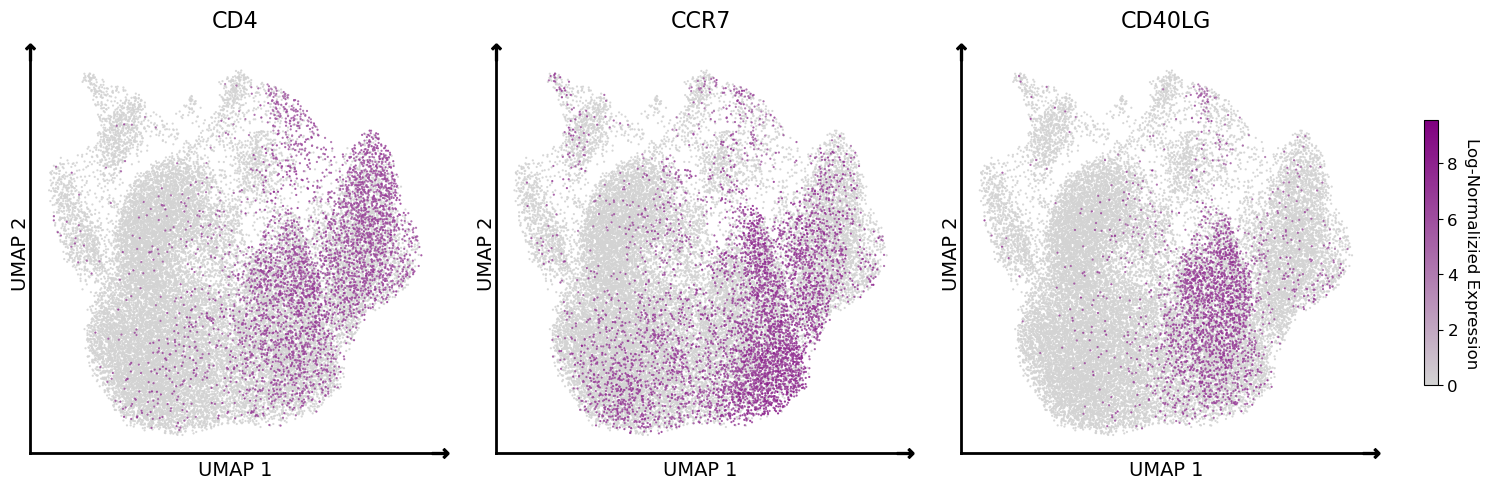

In [29]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

# 1. Custom colors
colors = ["lightgrey", "purple"]
cmap_grey_purple = LinearSegmentedColormap.from_list("grey_purple", colors, N=256)
plt.rcParams.update({'font.size': 12})

genes = ["CD4", "CCR7", "CD40LG"]

adata_T = sc.read("../h5ad/adata_T.h5ad")
sc.pp.normalize_total(adata_T, target_sum=1e6)
sc.pp.log1p(adata_T)

# 2. Unified range
vmin = 0
vmax = max(adata_T[:, g].X.max() if hasattr(adata_T[:, g].X, 'max') else adata_T[:, g].X.toarray().max() for g in genes)

# 3. Create canvas
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for i, gene in enumerate(genes):
    sc.pl.umap(
        adata_T, 
        color=gene, 
        ax=axes[i],
        show=False,
        size=10,
        alpha=0.9,
        cmap=cmap_grey_purple, 
        frameon=False,
        colorbar_loc=None, 
        vmin=vmin, 
        vmax=vmax,
        title=gene,
        legend_loc=None
    )
    axes[i].set_title(gene, fontsize=16, pad=0)  # pad controls the distance between the title and the plot

# 4. Adjust layout
plt.tight_layout()  # reserve space on the right

# 5. Manually add a shared colorbar
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
sm = mpl.cm.ScalarMappable(cmap=cmap_grey_purple, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes, shrink=0.6, aspect=20, pad=0.02)
cbar.set_label('Log-Normalizied Expression', rotation=270, labelpad=15)

# 6. Set axis styles, arrows, and labels
for i, gene in enumerate(genes):
    ax = axes[i]

    # --- 1. Get data boundaries ---
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    # --- 2. Draw a clean L-shaped baseline ---
    # Hide default spines
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Draw L-shaped solid lines
    ax.plot([xmin, xmax], [ymin, ymin], color='black', linewidth=2.0, transform=ax.transData, clip_on=False)  # X-axis
    ax.plot([xmin, xmin], [ymin, ymax], color='black', linewidth=2.0, transform=ax.transData, clip_on=False)  # Y-axis

    # --- 3. Draw arrowheads ---
    # X-axis arrow
    ax.plot(xmax, ymin, marker=r'$\rightarrow$', markersize=12, color='black', transform=ax.transData, clip_on=False)
    # Y-axis arrow
    ax.plot(xmin, ymax, marker=r'$\uparrow$', markersize=12, color='black', transform=ax.transData, clip_on=False)

    # --- 4. Set labels (centered) ---
    # Calculate midpoints
    x_mid = (xmin + xmax) / 2
    y_mid = (ymin + ymax) / 2

    # X-axis label: placed directly below the bottom axis
    # verticalalignment='top' ensures the text top aligns with the coordinate, making it look tighter
    ax.text(x_mid, ymin-0.8, "UMAP 1", transform=ax.transData, fontsize=14,
            verticalalignment='top', horizontalalignment='center', clip_on=False)

    # Y-axis label: placed directly to the left of the left axis
    # rotation=90 makes the text vertical
    # horizontalalignment='right' aligns the text to the right against the axis
    ax.text(xmin, y_mid, "UMAP 2", transform=ax.transData, fontsize=14,
            rotation=90, verticalalignment='center', horizontalalignment='right', clip_on=False)
plt.show()